# Object detection thresholding

Pipeline: preprocessing (median filter), transformasi HSV, threshold warna biru/ungu, morfologi, ground truth Pascal VOC, visualisasi, dan evaluasi precision/recall/F1.

Ukuran: 549 x 310


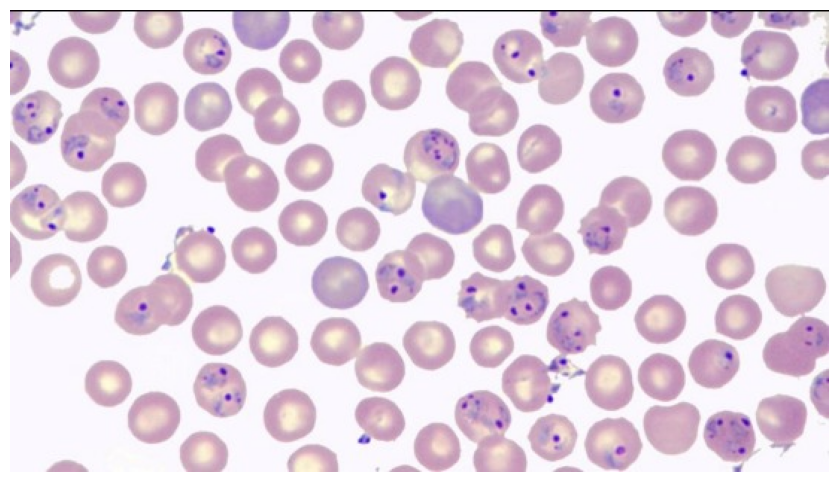

In [2]:
from pathlib import Path
from xml.etree import ElementTree as ET
import cv2
import numpy as np
import matplotlib.pyplot as plt

BASE = Path.cwd()
if not (BASE / 'RawData.jpeg').exists(): BASE = Path(r'G:\Semester 7\visi komputer\Minggu 5')
raw_path, gt_path = BASE / 'RawData.jpeg', BASE / 'ground_truth.xml'
raw_bgr = cv2.imread(str(raw_path))
if raw_bgr is None: raise FileNotFoundError(raw_path)
raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
print('Ukuran:', raw_rgb.shape[1], 'x', raw_rgb.shape[0])
plt.figure(figsize=(12, 6)); plt.imshow(raw_rgb); plt.axis('off'); plt.show()

Ground truth: 28 | Kandidat deteksi: 49


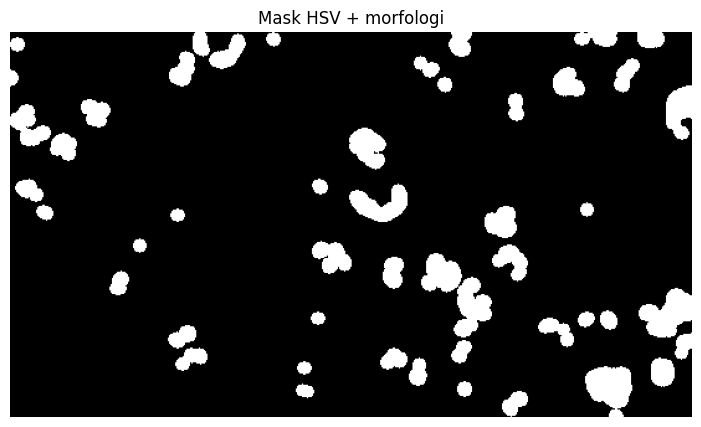

In [3]:
def read_pascal_voc(path):
    root = ET.parse(path).getroot(); result = []
    for obj in root.findall('object'):
        b = obj.find('bndbox')
        result.append([int(b.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
    return np.asarray(result, dtype=np.int32)

gt_boxes = read_pascal_voc(gt_path)    
def detect_threshold(image_bgr, h_low=105, h_high=179, s_low=65, v_high=205,
                     min_area=18, max_area=1800):
    filtered = cv2.medianBlur(image_bgr, 3)
    hsv = cv2.cvtColor(filtered, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, np.array([h_low, s_low, 20]),
                       np.array([h_high, 255, v_high]))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,
                            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))
    mask = cv2.dilate(mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = [[x, y, x + w - 1, y + h - 1] for x, y, w, h, area in stats[1:]
             if min_area <= area <= max_area and w >= 5 and h >= 5]
    return mask, np.asarray(boxes, dtype=np.int32)

mask, predicted_boxes = detect_threshold(raw_bgr)
print('Ground truth:', len(gt_boxes), '| Kandidat deteksi:', len(predicted_boxes))
plt.figure(figsize=(12, 5)); plt.imshow(mask, cmap='gray'); plt.axis('off'); plt.title('Mask HSV + morfologi'); plt.show()

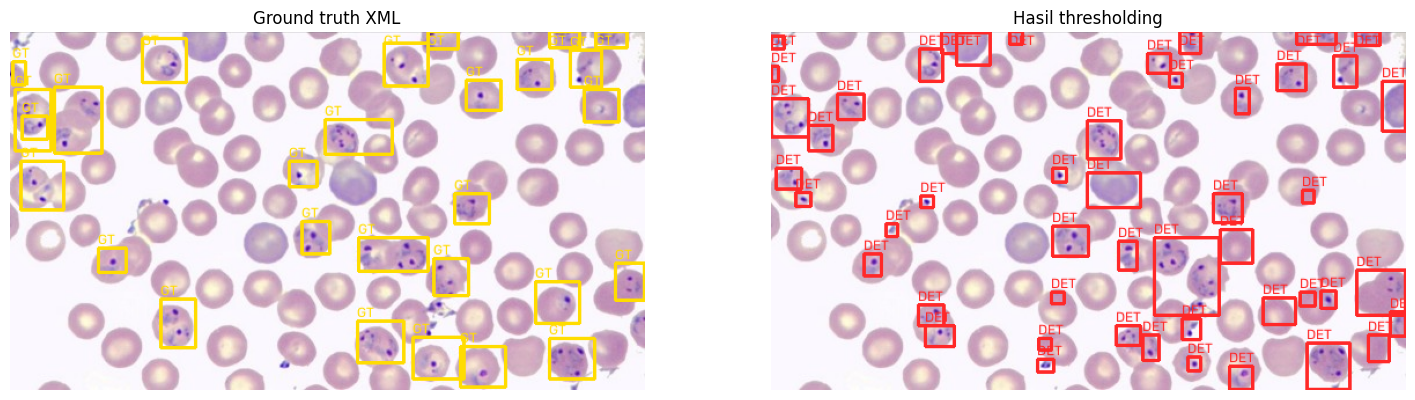

In [4]:
def draw_boxes(image, boxes, color, label):
    out = image.copy()
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(out, (x1, y1), (x2, y2), color, 2)
        cv2.putText(out, label, (x1, max(12, y1 - 3)), cv2.FONT_HERSHEY_SIMPLEX, .4, color, 1)
    return out

fig, ax = plt.subplots(1, 2, figsize=(18, 6))
ax[0].imshow(draw_boxes(raw_rgb, gt_boxes, (255, 220, 0), 'GT')); ax[0].set_title('Ground truth XML')
ax[1].imshow(draw_boxes(raw_rgb, predicted_boxes, (255, 40, 40), 'DET')); ax[1].set_title('Hasil thresholding')
for a in ax: a.axis('off')
plt.show()

In [5]:
def iou(a, b):
    x1, y1, x2, y2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2-x1+1) * max(0, y2-y1+1)
    aa = (a[2]-a[0]+1) * (a[3]-a[1]+1); ab = (b[2]-b[0]+1) * (b[3]-b[1]+1)
    return inter / (aa + ab - inter) if aa + ab - inter else 0.0

def evaluate(predictions, truths, threshold=.20):
    matched, tp = set(), 0
    for p in predictions:
        candidates = [(iou(p, t), i) for i, t in enumerate(truths) if i not in matched]
        score, index = max(candidates, default=(0.0, -1))
        if score >= threshold: tp += 1; matched.add(index)
    fp, fn = len(predictions)-tp, len(truths)-tp
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0.0
    return {'TP': tp, 'FP': fp, 'FN': fn, 'precision': precision, 'recall': recall, 'f1_score': f1}

metrics = evaluate(predicted_boxes, gt_boxes)
for key, value in metrics.items(): print(f'{key}: {value:.4f}' if isinstance(value, float) else f'{key}: {value}')
print('IoU threshold = 0.20; gunakan threshold ini karena GT menandai sel/area, sedangkan deteksi mengambil piksel target.')

TP: 22
FP: 27
FN: 6
precision: 0.4490
recall: 0.7857
f1_score: 0.5714
IoU threshold = 0.20; gunakan threshold ini karena GT menandai sel/area, sedangkan deteksi mengambil piksel target.
